In [6]:
import pandas as pd
import matplotlib.pyplot as plt

from banco import get_engine, executar

engine = get_engine()
pd.set_option("display.max_colwidth", 80)
pd.options.display.float_format = "{:,.2f}".format

def consulta(sql):
    return pd.read_sql(sql, engine)

def grafico_barras(df, rotulo, valor, titulo, eixo_x):
    d = df.sort_values(valor).copy()
    d[rotulo] = d[rotulo].astype(str).str.slice(0,45)
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(d) + 2))
    ax.barh(d[rotulo], d[valor].astype(float))
    ax.set_title(titulo)
    ax.set_xlabel(eixo_x)
    ax.ticklabel_format(axis="x", style="plain")
    plt.tight_layout()
    plt.show()

,nome_orgao_superior,qtd_viagens,custo_total
0,Ministério da Justiça e Segurança Pública,75742,"486,933,121.65"
1,Ministério da Defesa,61912,"156,070,304.49"
2,Ministério da Educação,65295,"111,291,349.34"
3,Ministério do Meio Ambiente e Mudança do Clima,19413,"49,697,710.16"
4,Ministério da Previdência Social,8190,"40,417,309.06"


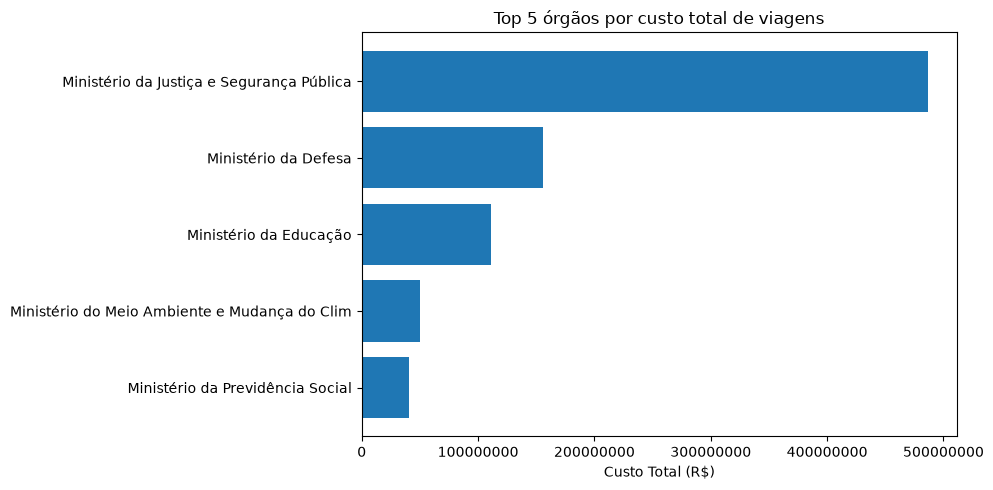

In [7]:
#Part 1 - Perguntas respondidas na Silver
# 1 - Quais os 5 órgãos com maior custo total?
SQL_Q1 = """
SELECT 
    nome_orgao_superior,
    count(*) as qtd_viagens,
    sum(valor_total) as custo_total
FROM 
silver_viagem
GROUP BY nome_orgao_superior
ORDER BY custo_total DESC
LIMIT 5
"""
q1 = consulta(SQL_Q1)
display(q1)
grafico_barras(q1, "nome_orgao_superior", "custo_total",
               "Top 5 órgãos por custo total de viagens", "Custo Total (R$)")


,destinos,qtd_viagens,custo_medio
0,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita, Rio de Janeiro/RJ",1,"245,852.80"
1,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC, Rio Branco/AC, Brasília/DF, ...",1,"216,729.36"
2,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis/RJ, Rio de Janeiro/RJ, Brasíl...",1,"207,220.14"


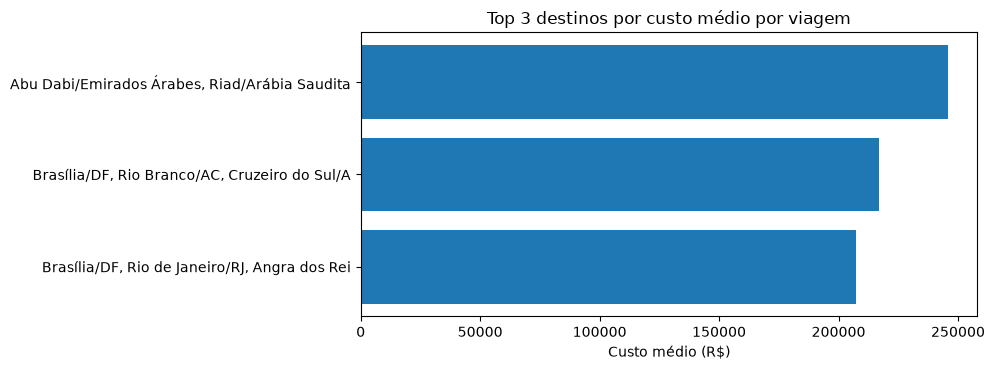

In [3]:
# 2 - Quais os 3 destinos com maior custo médio por viagem?
SQL_Q2 = """
SELECT 
    destinos,
    count(*) as qtd_viagens,
    avg(valor_total) as custo_medio
FROM
silver_viagem
where
destinos is not null
group by destinos
order by custo_medio desc
limit 3
"""
q2 = consulta(SQL_Q2)
display(q2)
grafico_barras(q2, "destinos", "custo_medio",
               "Top 3 destinos por custo médio por viagem", "Custo médio (R$)")

In [4]:
SQL_Q2B = """

SELECT 
    destinos,
    count(*) as qtd_viagens,
    avg(valor_total) as custo_medio
FROM
silver_viagem
where
destinos is not null
group by destinos
having count(*) >= 30
order by custo_medio desc
limit 3
"""
display(consulta(SQL_Q2B))

,destinos,qtd_viagens,custo_medio
0,"Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF",91,"105,470.37"
1,"Brasília/DF, Brasília/DF, Brasília/DF",88,"100,317.26"
2,"Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF",47,"97,736.69"


,id_viagem,nome_orgao_superior,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,Ministério da Previdência Social,2025-01-13,2026-01-31,384,0.00
1,0000000000020793594,Ministério da Justiça e Segurança Pública,2025-01-02,2026-01-15,379,"120,650.00"
2,0000000000020793492,Ministério da Justiça e Segurança Pública,2025-01-11,2026-01-15,370,"113,382.50"
3,0000000000020774569,Ministério da Educação,2025-02-26,2026-03-02,370,0.00
4,0000000000020592696,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,367,"159,044.90"
5,0000000000020685666,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,367,"124,312.50"
6,0000000000020589962,Ministério da Educação,2025-02-23,2026-02-23,366,0.00
7,0000000000020732132,Ministério da Educação,2025-03-31,2026-03-31,366,0.00
8,0000000000020557147,Ministério da Justiça e Segurança Pública,2025-01-01,2025-12-31,365,"216,729.36"
9,0000000000020649880,Ministério da Justiça e Segurança Pública,2025-01-01,2025-12-31,365,"207,220.14"


Resposta: viagem 0000000000020699856 - 384 dias, custo total R$ 0.00


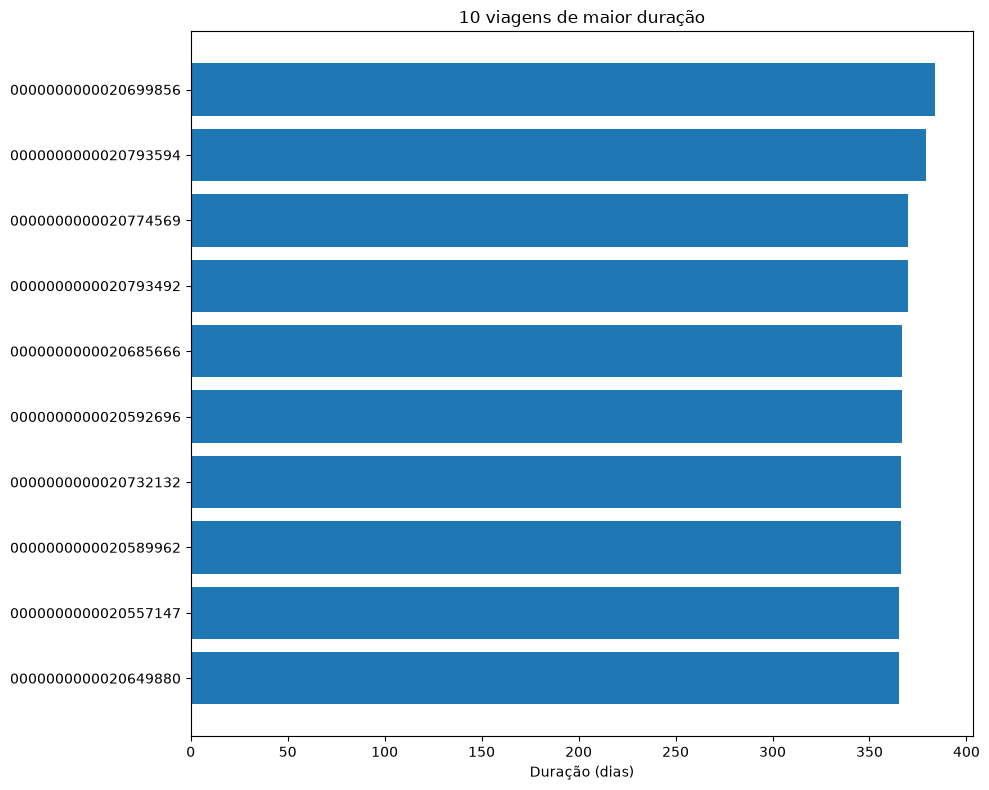

In [5]:
# 3 - Qual a viagem de maior duração e qual o seu custo total?
SQL_Q3 = """

SELECT 
    id_viagem, 
    nome_orgao_superior, 
    data_inicio, 
    data_fim,
    duracao_dias, 
    valor_total
FROM silver_viagem
where
duracao_dias is not null
order by duracao_dias desc, valor_total desc
limit 10
"""

q3 = consulta(SQL_Q3)
display(q3)
top = q3.iloc[0]
print(f"Resposta: viagem {top['id_viagem']} - {top['duracao_dias']} dias, "
      f"custo total R$ {top['valor_total']:,.2f}")
grafico_barras(q3, "id_viagem", "duracao_dias",
               "10 viagens de maior duração", "Duração (dias)")


In [30]:
#Parte 2 - Camada Gold
#Duas tabelas agregadas com JOIN + GROUP BY
GOLD_PAGAMENTOS = """
SELECT
    p.tipo_pagamento,
    p.nome_orgao_pagador,
    count(*) as qtd_pagamentos,
    sum(p.valor) as valor_total,
    round(avg(p.valor), 2) as valor_medio
FROM
silver_pagamento p
JOIN silver_viagem v ON v.id_viagem = p.id_viagem
GROUP BY p.tipo_pagamento, p.nome_orgao_pagador

"""
GOLD_TRECHOS = """
SELECT 
    t.meio_transporte,
    t.destino_uf,
    count(*) as qtd_trechos
FROM
silver_trecho t
JOIN silver_viagem v ON v.id_viagem = t.id_viagem
GROUP BY t.meio_transporte, t.destino_uf
"""

for nome, sql in {"gold_pagamentos": GOLD_PAGAMENTOS,
                  "gold_trechos":GOLD_TRECHOS}.items():
    executar(f"DROP TABLE IF EXISTS {nome}")
    executar(f"CREATE TABLE {nome} AS {sql}")
    executar(f"CREATE OR REPLACE VIEW vw_{nome} AS {sql}")

display(consulta("SELECT * FROM gold_pagamentos LIMIT 5"))
display(consulta("SELECT * FROM gold_trechos limit 5"))



,tipo_pagamento,nome_orgao_pagador,qtd_pagamentos,valor_total,valor_medio
0,DIÁRIAS,Advocacia-Geral da União - Unidades com vínculo direto,1306,"1,808,301.59","1,384.61"
1,DIÁRIAS,Agência Espacial Brasileira,179,"340,293.97","1,901.08"
2,DIÁRIAS,Agência Nacional de Águas e Saneamento Básico,413,"594,737.38","1,440.04"
3,DIÁRIAS,Agência Nacional de Aviação Civil,2607,"3,893,023.56","1,493.30"
4,DIÁRIAS,Agência Nacional de Energia Elétrica,372,"615,611.21","1,654.87"


,meio_transporte,destino_uf,qtd_trechos
0,Aéreo,Acre,2233
1,Aéreo,Alagoas,1576
2,Aéreo,Amapá,1501
3,Aéreo,Amazonas,11856
4,Aéreo,Bahia,5604


,tipo_pagamento,qtd_pagamentos,valor_medio
0,DIÁRIAS,"401,463.00","2,078.28"
1,PASSAGEM,"188,985.00","1,878.34"
2,Serviço correlato: seguro,"4,894.00",447.51
3,RESTITUIÇÃO,"11,574.00",245.70


Resposta: DIÁRIAS


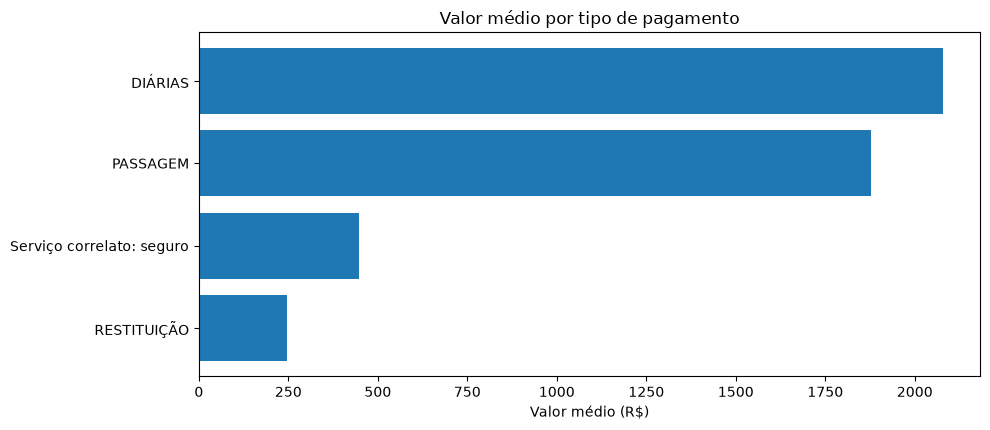

In [31]:
# 4 - Qual o tipo de pagamento com maior valor médio?
SQL_Q4 = """
SELECT 
    tipo_pagamento,
    sum(qtd_pagamentos) as qtd_pagamentos,
    sum(valor_total) / sum(qtd_pagamentos) as valor_medio
FROM
gold_pagamentos
GROUP BY tipo_pagamento
order by valor_medio desc

"""
q4 = consulta(SQL_Q4)
display(q4)
print(f"Resposta: {q4.iloc[0]['tipo_pagamento']}")
grafico_barras(q4, "tipo_pagamento", "valor_medio",
               "Valor médio por tipo de pagamento", "Valor médio (R$)")


,meio_transporte,qtd_trechos
0,Veículo Oficial,"386,424.00"
1,Aéreo,"232,666.00"
2,Rodoviário,"64,970.00"
3,Veículo Próprio,"42,846.00"
4,Inválido,"26,659.00"
5,Fluvial,"8,429.00"
6,Ferroviário,874.00
7,Marítimo,481.00


Resposta: Veículo Oficial


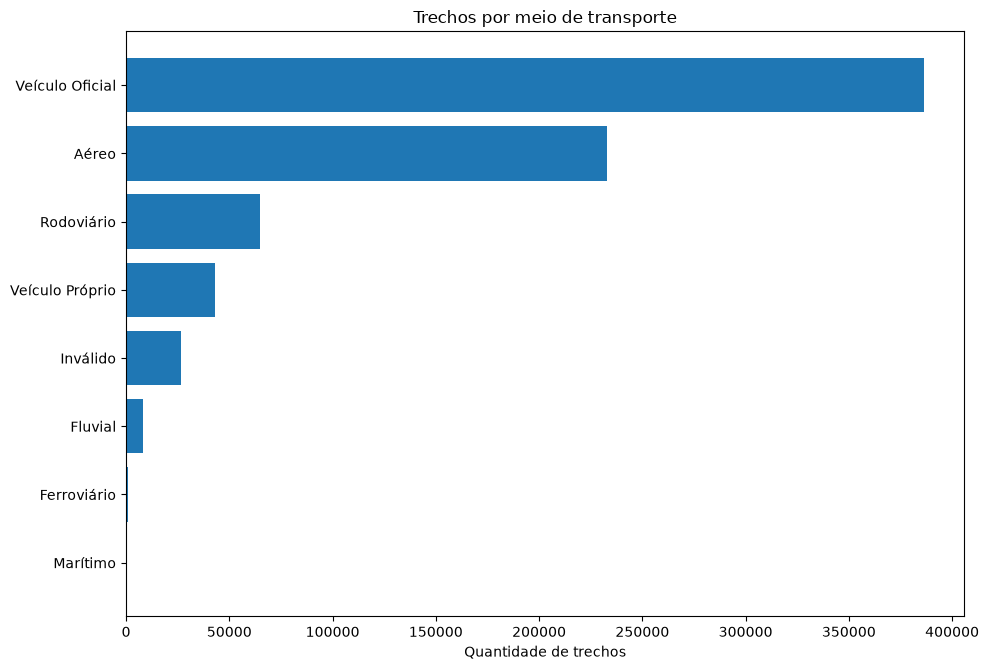

In [32]:
# 5 - Qual o meio de transporte mais usado nos trechos?
SQL_Q5 = """
SELECT
    meio_transporte,
    sum(qtd_trechos) as qtd_trechos
FROM
gold_trechos
GROUP BY meio_transporte
order by qtd_trechos desc

"""
q5 = consulta(SQL_Q5)
display(q5)
print(f"Resposta: {q5.iloc[0]['meio_transporte']}")
grafico_barras(q5, "meio_transporte", "qtd_trechos",
               "Trechos por meio de transporte", "Quantidade de trechos")

,destino_uf,qtd_trechos
0,São Paulo,"82,722.00"
1,Distrito Federal,"79,962.00"
2,Minas Gerais,"50,965.00"
3,Rio de Janeiro,"44,197.00"
4,Paraná,"42,603.00"
5,Pará,"40,044.00"
6,Rio Grande do Sul,"38,684.00"
7,Mato Grosso do Sul,"30,516.00"
8,Bahia,"28,375.00"
9,Pernambuco,"28,372.00"


Resposa: São Paulo


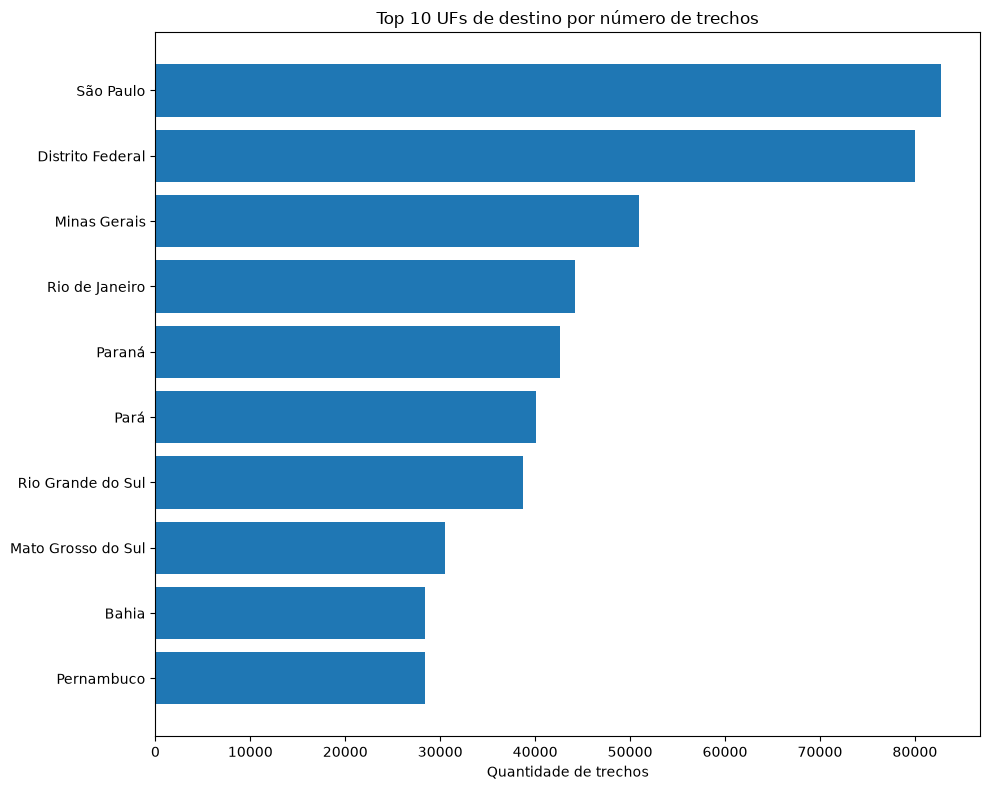

In [33]:
# 6 - Qual UF de destino aparece em mais trechos?
SQL_Q6 = """
SELECT 
    destino_uf,
    sum(qtd_trechos) as qtd_trechos
    
FROM
gold_trechos
GROUP BY destino_uf
ORDER BY qtd_trechos desc
limit 10

"""
q6 = consulta(SQL_Q6)
display(q6)
print(f"Resposa: {q6.iloc[0]['destino_uf']}")
grafico_barras(q6, "destino_uf", "qtd_trechos",
               "Top 10 UFs de destino por número de trechos",
               "Quantidade de trechos")


In [34]:
# 7 - Qual órgão pagou mais no total?
SQL_Q7 = """
select 
    nome_orgao_pagador,
    sum(valor_total) as valor_total
FROM
gold_pagamentos
group by nome_orgao_pagador
order by valor_total desc

"""
q7 = consulta(SQL_Q7)
display(q7)
print(f"resposta: {q7.iloc[0]['nome_orgao_pagador']} - "
      f"R$ {q7.iloc[0]['valor_total']:,.2f}")



,nome_orgao_pagador,valor_total
0,Fundo Nacional de Segurança Pública,"278,481,047.89"
1,Sigiloso,"200,484,801.68"
2,Comando da Aeronáutica,"81,769,144.77"
3,Instituto Nacional do Seguro Social,"37,427,601.45"
4,Comando do Exército,"36,872,643.95"
...,...,...
211,"Instituto Federal de Educação, Ciência e Tecnologia de Brasília","32,877.29"
212,Fundação Osório,"8,737.50"
213,Fundo Nacional sobre Mudança no Clima,"4,821.45"
214,Fundo Penitenciário Nacional,"1,918.59"


resposta: Fundo Nacional de Segurança Pública - R$ 278,481,047.89
